# Atividade — Logic Tensor Networks

Integrantes:
- Camila dos Santos Soares
- Daniel Nunes Santos
- José Eduardo Araujo Costa Melo
- Nicoly Lima de Souza

- Pedro Matheus Melo Pereira
- Pedro Vinícius Díaz de Alencar

Base: notebook do professor (19/11/2026) e tutorial PDF (20/11/2026).
Execute as células na ordem. O tutorial base foi mantido, com ajustes de execução.
A atividade geométrica está na Parte 2. As saídas abaixo são de uma execução real.

## Instalação (somente se precisar)
No Colab, execute a célula abaixo uma vez. Se pedir reinício, reinicie a sessão e depois execute a partir dos imports.
No ambiente já instalado, ela apenas verifica os módulos. Usamos CPU para evitar mistura entre tensores CPU e GPU.

In [1]:
import importlib.util
import subprocess
import sys
if importlib.util.find_spec("ltn") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "numpy==1.26.4", "torch", "matplotlib", "git+https://github.com/tommasocarraro/LTNtorch.git"])
print("Instalação disponível. Se o ambiente pedir reinício, reinicie antes de continuar.")

Instalação disponível. Se o ambiente pedir reinício, reinicie antes de continuar.


## Parte 1 — Tutorial base
A variável da regra vermelho → redondo agora é a mesma no antecedente e no consequente, e os pontos são fixos.

In [2]:
#!/usr/bin/env python
# coding: utf-8

# In[32]:
import torch
import torch.nn as nn
import ltn
import numpy as np
import matplotlib.pyplot as plt
import random
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
torch.set_num_threads(2)

In [3]:
ltn.device = torch.device("cpu")
print("Dispositivo:", ltn.device)

Dispositivo: cpu


In [4]:
# In[34]:
# 1. DEFINIR CONECTIVOS LÓGICOS E QUANTIFICADORES (REQUERIDOS NO LTNTORCH)
Not = ltn.Connective(ltn.fuzzy_ops.NotStandard())
And = ltn.Connective(ltn.fuzzy_ops.AndProd())
Or = ltn.Connective(ltn.fuzzy_ops.OrProbSum())
Implies = ltn.Connective(ltn.fuzzy_ops.ImpliesReichenbach())
Forall = ltn.Quantifier(ltn.fuzzy_ops.AggregPMeanError(p=2), quantifier="f")
Exists = ltn.Quantifier(ltn.fuzzy_ops.AggregPMean(p=2), quantifier="e")
sat_agg = ltn.fuzzy_ops.SatAgg()

In [5]:
# In[35]:
# 2. CRIAR OBJETOS LTN (Constantes e Variáveis)
red_ball = ltn.Constant(torch.tensor([1.0, 0.0, 0.0]), trainable=False)
blue_cube = ltn.Constant(torch.tensor([0.0, 0.0, 1.0]), trainable=False)

balls = ltn.Variable("balls", torch.tensor([
    [1.0, 0.0, 0.0],
    [0.0, 1.0, 0.0],
    [0.5, 0.0, 0.5],
]))
cubes = ltn.Variable("cubes", torch.tensor([
    [0.0, 0.0, 1.0],
    [1.0, 1.0, 0.0],
    [0.5, 0.5, 0.5],
]))

In [6]:
# In[36]:
# 3. DEFINIR PREDICADOS (Propriedades/relações lógicas)
class ColorPredicate(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(3, 10),
            nn.ReLU(),
            nn.Linear(10, 1),
            nn.Sigmoid()
        )
    def forward(self, x):
        if hasattr(x, 'value'):
            x = x.value
        return self.network(x).squeeze(-1)

In [7]:
is_red = ltn.Predicate(ColorPredicate())
is_blue = ltn.Predicate(ColorPredicate())
is_round = ltn.Predicate(ColorPredicate())

In [8]:
base_x = ltn.Variable("base_x", torch.randn(10, 3))
def axioms():
    return sat_agg(
        is_red(red_ball), is_blue(blue_cube), is_round(red_ball),
        Not(is_round(blue_cube)), Forall(balls, is_round(balls)),
        Forall(base_x, Implies(is_red(base_x), is_round(base_x)))
    )

In [9]:
# 5. VERIFICAÇÃO DE SATISFATÓRIA (Raciocínio)
def check_satisfiability():
    sat_level = axioms()
    print(f"Knowledge base satisfaction level: {sat_level.item():.4f}")
    return sat_level

In [10]:
# 6. TREINAMENTO DOS PREDICADOS (Aprendendo com os dados)
def train_predicates(epochs=100):
    parameters = list(is_red.model.parameters()) + \
                 list(is_blue.model.parameters()) + \
                 list(is_round.model.parameters())
    optimizer = torch.optim.Adam(parameters, lr=0.01)
    print("\n=== TRAINING PREDICATES ===")
    for epoch in range(epochs):
        optimizer.zero_grad()
        sat_loss = 1 - axioms()
        sat_loss.backward()
        optimizer.step()
        if epoch % 20 == 0:
            print(f"Epoch {epoch}: Satisfaction = {1-sat_loss.item():.4f}")

In [11]:
# In[43]:
# 7. QUERYING THE KNOWLEDGE BASE (Inference)
def query_knowledge_base():
    print("\n=== QUERYING KNOWLEDGE BASE ===")
    # Query 1: Is the red ball red?
    query1 = is_red(red_ball)
    print(f"Q1: Is the red ball red? A: {query1.value.item():.4f}")

    # Query 2: Is the blue cube round?
    query2 = is_round(blue_cube)
    print(f"Q2: Is the blue cube round? A: {query2.value.item():.4f}")

    # Query 3: Are all balls round? (Universal quantification)
    all_balls_round = Forall(balls, is_round(balls))
    print(f"Q3: Are all balls round? A: {all_balls_round.value.item():.4f}")

In [12]:
# 8. EXECUTE O EXEMPLO COMPLETO
print("=== EXEMPLO DE RACIOCÍNIO LÓGICO LTN ===")
initial_sat = check_satisfiability()
train_predicates(epochs=100)
final_sat = check_satisfiability()
query_knowledge_base()
print("\n=== PRINCIPAIS INFORMAÇÕES SOBRE O LTNObjects ===")
print("1. LTNObjects encapsulam tensores com significado lógico.")
print("2. Constantes representam entidades específicas")
print("3. As variáveis representam conjuntos quantificáveis")
print("4. Os predicados mapeiam LTNObjects para valores de verdade [0,1]")
print("5. Os conectivos lógicos (E, Ou, Não, Implica) operam sobre valores de verdade.")
print("6. Os quantificadores (Forall, Exists) agregam sobre a variávels")
print("7. No LTNTorch, você deve definir explicitamente todos os conectivos lógicos.")
print("8. A função SatAgg combina múltiplos axiomas em uma única pontuação de satisfação.")

=== EXEMPLO DE RACIOCÍNIO LÓGICO LTN ===
Knowledge base satisfaction level: 0.5198

=== TRAINING PREDICATES ===
Epoch 0: Satisfaction = 0.5198
Epoch 20: Satisfaction = 0.6376
Epoch 40: Satisfaction = 0.7692
Epoch 60: Satisfaction = 0.8780
Epoch 80: Satisfaction = 0.9432
Knowledge base satisfaction level: 0.9713

=== QUERYING KNOWLEDGE BASE ===
Q1: Is the red ball red? A: 0.9848
Q2: Is the blue cube round? A: 0.0413
Q3: Are all balls round? A: 0.9546

=== PRINCIPAIS INFORMAÇÕES SOBRE O LTNObjects ===
1. LTNObjects encapsulam tensores com significado lógico.
2. Constantes representam entidades específicas
3. As variáveis representam conjuntos quantificáveis
4. Os predicados mapeiam LTNObjects para valores de verdade [0,1]
5. Os conectivos lógicos (E, Ou, Não, Implica) operam sobre valores de verdade.
6. Os quantificadores (Forall, Exists) agregam sobre a variávels
7. No LTNTorch, você deve definir explicitamente todos os conectivos lógicos.
8. A função SatAgg combina múltiplos axiomas em

In [13]:
# ==============================================================================
# EXTENSÃO: DIFERENTES FORMAS DE IGUALDADE EM LTN (Extensão Original)
# ==============================================================================
# In[45]:
print("\n" + "="*50)
print("EXTENSION: DIFFERENT FORMS OF EQUALITY IN LTN")
print("="*50)


EXTENSION: DIFFERENT FORMS OF EQUALITY IN LTN


In [14]:
Not_eq = ltn.Connective(ltn.fuzzy_ops.NotStandard())
And_eq = ltn.Connective(ltn.fuzzy_ops.AndProd())
Or_eq = ltn.Connective(ltn.fuzzy_ops.OrProbSum())
Implies_eq = ltn.Connective(ltn.fuzzy_ops.ImpliesReichenbach())
Forall_eq = ltn.Quantifier(ltn.fuzzy_ops.AggregPMeanError(p=2), quantifier="f")
Exists_eq = ltn.Quantifier(ltn.fuzzy_ops.AggregPMean(p=2), quantifier="e")
sat_agg_eq = ltn.fuzzy_ops.SatAgg()

In [15]:
red_object1 = ltn.Constant(torch.tensor([1.0, 0.0, 0.0], device=ltn.device), trainable=True)
red_object2 = ltn.Constant(torch.tensor([0.95, 0.05, 0.0], device=ltn.device), trainable=True)
blue_object = ltn.Constant(torch.tensor([0.0, 0.0, 1.0], device=ltn.device), trainable=True)

objects = ltn.Variable("objetos", torch.tensor([
    [1.0, 0.0, 0.0],
    [0.95, 0.05, 0.0],
    [0.0, 0.0, 1.0],
    [0.0, 1.0, 0.0],
], device=ltn.device))
print("Experimento sobre igualdade: configuração concluída!")

# In[46]: 1. Igualdade diagonal LTN
print("\n" + "-"*30)
print("1. IGUALDADE DIAGONAL LTN")
print("-"*30)

Experimento sobre igualdade: configuração concluída!

------------------------------
1. IGUALDADE DIAGONAL LTN
------------------------------


In [16]:
class DiagonalEquality(nn.Module):
    def forward(self, x, y):
        x_val = x.value if hasattr(x, 'value') else x
        y_val = y.value if hasattr(y, 'value') else y
        cos_sim = torch.nn.functional.cosine_similarity(x_val, y_val, dim=-1)
        return 0.5 * (cos_sim + 1.0)

In [17]:
# Teste da Igualdade diagonal euclidiana
Equal_Diag = ltn.Predicate(DiagonalEquality().to(ltn.device))

In [18]:
def axioms_withEquality_Diag():
    axioms = [
        Forall_eq(objects, Equal_Diag(objects, objects)),
        Equal_Diag(red_object1, red_object2),
        Equal_Diag(red_object2, red_object1),
        Implies_eq(And_eq(Equal_Diag(red_object1, red_object2), Equal_Diag(red_object2, red_object1)), Equal_Diag(red_object1, red_object1)),
        Not_eq(Equal_Diag(red_object1, blue_object))
    ]
    return sat_agg_eq(*axioms)

In [19]:
print("Testando a igualdade diagonal...")
sat_diag = axioms_withEquality_Diag()
print(f"Satisfação KB de igualdade diagonal: {sat_diag.item():.4f}")
print(f"P: Os dois objetos vermelhos são iguais? R: {Equal_Diag(red_object1, red_object2).value.item():.4f}")
print(f"P: Um objeto vermelho é igual a um objeto azul? R: {Equal_Diag(red_object1, blue_object).value.item():.4f}")

# In[50]: 2. Igualdade de cosseno
print("\n" + "-"*30)
print("2. IGUALDADE DE COSSENO.")
print("-"*30)

Testando a igualdade diagonal...
Satisfação KB de igualdade diagonal: 0.7764
P: Os dois objetos vermelhos são iguais? R: 0.9993
P: Um objeto vermelho é igual a um objeto azul? R: 0.5000

------------------------------
2. IGUALDADE DE COSSENO.
------------------------------


In [20]:
class CosineEquality(nn.Module):
    def __init__(self):
        super().__init__()
        self.temperature = nn.Parameter(torch.tensor(1.0, device=ltn.device))
    def forward(self, x, y):
        x_val = x.value if hasattr(x, 'value') else x
        y_val = y.value if hasattr(y, 'value') else y
        cos_sim = torch.nn.functional.cosine_similarity(x_val, y_val, dim=-1)
        return torch.sigmoid(self.temperature * (cos_sim + 1.0) / 2.0)

Equal_Cos = ltn.Predicate(CosineEquality().to(ltn.device))

In [21]:
def axioms_withEquality_Cos():
    parameters = list(Equal_Cos.model.parameters())
    optimizer = torch.optim.Adam(parameters, lr=0.1)
    print("Treinamento da Igualdade do Cosseno...")
    for epoch in range(200):
        optimizer.zero_grad()
        axioms = [Forall_eq(objects, Equal_Cos(objects, objects)), Equal_Cos(red_object1, red_object2), Equal_Cos(red_object2, red_object1), Not_eq(Equal_Cos(red_object1, blue_object))]
        sat = sat_agg_eq(*axioms)
        loss = 1 - sat
        loss.backward()
        optimizer.step()
        if epoch % 50 == 0:
            print(f"Época {epoch}: Satisfatibilidade da igualdade do cosseno = {sat.item():.4f}, Temp = {Equal_Cos.model.temperature.item():.4f}")
    return sat_agg_eq(Forall_eq(objects, Equal_Cos(objects, objects)), Equal_Cos(red_object1, red_object2), Not_eq(Equal_Cos(red_object1, blue_object)))

sat_cos = axioms_withEquality_Cos()
print(f"Satisfatibilidade KB da Igualdade do Cosseno Final: {sat_cos.item():.4f}")
print(f"Q: Os dois objetos vermelhos são iguais (cosseno)? A: {Equal_Cos(red_object1, red_object2).value.item():.4f}")
print(f"Q: O objeto vermelho é igual ao objeto azul (cosseno)? A: {Equal_Cos(red_object1, blue_object).value.item():.4f}")

Treinamento da Igualdade do Cosseno...
Época 0: Satisfatibilidade da igualdade do cosseno = 0.6112, Temp = 1.1000
Época 50: Satisfatibilidade da igualdade do cosseno = 0.6255, Temp = 1.5738
Época 100: Satisfatibilidade da igualdade do cosseno = 0.6255, Temp = 1.5680
Época 150: Satisfatibilidade da igualdade do cosseno = 0.6255, Temp = 1.5687
Satisfatibilidade KB da Igualdade do Cosseno Final: 0.5793
Q: Os dois objetos vermelhos são iguais (cosseno)? A: 0.8275
Q: O objeto vermelho é igual ao objeto azul (cosseno)? A: 0.6866


In [22]:
# In[51]: 3. Igualdade Euclidiana
print("\n" + "-"*30)
print("3. IGUALDADE EUCLIDIANA")
print("-"*30)


------------------------------
3. IGUALDADE EUCLIDIANA
------------------------------


In [23]:
class EuclideanEquality(nn.Module):
    def __init__(self):
        super().__init__()
        self.gamma = nn.Parameter(torch.tensor(0.5, device=ltn.device))
    def forward(self, x, y):
        x_val = x.value if hasattr(x, 'value') else x
        y_val = y.value if hasattr(y, 'value') else y
        distance = torch.sum(torch.square(x_val - y_val), dim=-1)
        return torch.exp(-self.gamma * distance)

Equal_Eucl = ltn.Predicate(EuclideanEquality().to(ltn.device))

In [24]:
def axioms_withEquality_Eucl():
    parameters = list(Equal_Eucl.model.parameters())
    optimizer = torch.optim.Adam(parameters, lr=0.1)
    print("Treinamento em Igualdade Euclidiana...")
    for epoch in range(150):
        optimizer.zero_grad()
        axioms = [Forall_eq(objects, Equal_Eucl(objects, objects)), Equal_Eucl(red_object1, red_object2), Equal_Eucl(red_object2, red_object1), Not_eq(Equal_Eucl(red_object1, blue_object))]
        sat = sat_agg_eq(*axioms)
        loss = 1 - sat
        loss.backward()
        optimizer.step()
        if epoch % 30 == 0:
            print(f"Época {epoch}: Satisfatibilidade da Igualdade Euclidiana = {sat.item():.4f}, Gamma = {Equal_Eucl.model.gamma.item():.4f}")
    return sat_agg_eq(Forall_eq(objects, Equal_Eucl(objects, objects)), Equal_Eucl(red_object1, red_object2), Not_eq(Equal_Eucl(red_object1, blue_object)))

sat_eucl = axioms_withEquality_Eucl()
print(f"Satisfatibilidade final da igualdade euclidiana KB: {sat_eucl.item():.4f}")
print(f"Q: Os dois objetos vermelhos são iguais (euclidianos)? A: {Equal_Eucl(red_object1, red_object2).value.item():.4f}")
print(f"Q: O objeto vermelho é igual ao objeto azul (euclidiano)? A: {Equal_Eucl(red_object1, blue_object).value.item():.4f}")

Treinamento em Igualdade Euclidiana...
Época 0: Satisfatibilidade da Igualdade Euclidiana = 0.8160, Gamma = 0.6000
Época 30: Satisfatibilidade da Igualdade Euclidiana = 0.9903, Gamma = 2.2782
Época 60: Satisfatibilidade da Igualdade Euclidiana = 0.9905, Gamma = 2.4738
Época 90: Satisfatibilidade da Igualdade Euclidiana = 0.9905, Gamma = 2.4658
Época 120: Satisfatibilidade da Igualdade Euclidiana = 0.9905, Gamma = 2.4479
Satisfatibilidade final da igualdade euclidiana KB: 0.9917
Q: Os dois objetos vermelhos são iguais (euclidianos)? A: 0.9879
Q: O objeto vermelho é igual ao objeto azul (euclidiano)? A: 0.0076


In [25]:
# In[52]: 4. Igualdade de Variedades Aprendíveis
print("\n" + "-"*30)
print("4. IGUALDADE DE VARIEDADES APRENDÍVEIS")
print("-"*30)

class LearnableEquality(nn.Module):
    def __init__(self, input_dim=3):
        super(LearnableEquality, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim * 2, 64), nn.ELU(),
            nn.Linear(64, 32), nn.ELU(),
            nn.Linear(32, 1), nn.Sigmoid()
        )
    def forward(self, x, y):
        x_val = x.value if hasattr(x, 'value') else x
        y_val = y.value if hasattr(y, 'value') else y
        cat_inputs = torch.cat([x_val, y_val], dim=-1)
        return self.net(cat_inputs).squeeze(-1)

Equal_Learned = ltn.Predicate(LearnableEquality(input_dim=3).to(ltn.device))


------------------------------
4. IGUALDADE DE VARIEDADES APRENDÍVEIS
------------------------------


In [26]:
def axioms_withEquality_Learned():
    parameters = list(Equal_Learned.model.parameters())
    optimizer = torch.optim.Adam(parameters, lr=0.01)
    print("Treinaento da Rede de Igualdade aprodível...")
    for epoch in range(300):
        optimizer.zero_grad()
        axioms = [
            Forall_eq(objects, Equal_Learned(objects, objects)),
            Equal_Learned(red_object1, red_object2), Equal_Learned(red_object2, red_object1),
            Not_eq(Equal_Learned(red_object1, blue_object)), Not_eq(Equal_Learned(blue_object, red_object1)),
            Implies_eq(And_eq(Equal_Learned(red_object1, red_object2), Equal_Learned(red_object2, red_object1)), Equal_Learned(red_object1, red_object1))
        ]
        sat = sat_agg_eq(*axioms)
        loss = 1 - sat
        loss.backward()
        optimizer.step()
        if epoch % 50 == 0:
            print(f"Epoch {epoch}: Satisfatibilidade com a igualdade aprendível= {sat.item():.4f}")
    return sat_agg_eq(Forall_eq(objects, Equal_Learned(objects, objects)), Equal_Learned(red_object1, red_object2), Not_eq(Equal_Learned(red_object1, blue_object)))

sat_learned = axioms_withEquality_Learned()
print(f"Satisfação final com a base de conhecimento sobre igualdade aprendível: {sat_learned.item():.4f}")
print(f"Q:Os dois objetos vermelhos são iguais (Aprendido)? A: {Equal_Learned(red_object1, red_object2).value.item():.4f}")
print(f"Q: O objeto vermelho é igual ao objeto azul (aprendido)? A: {Equal_Learned(red_object1, blue_object).value.item():.4f}")
print(f"Q: O objeto vermelho é igual a si mesmo (Aprendido)? A: {Equal_Learned(red_object1, red_object1).value.item():.4f}")

Treinaento da Rede de Igualdade aprodível...
Epoch 0: Satisfatibilidade com a igualdade aprendível= 0.5410
Epoch 50: Satisfatibilidade com a igualdade aprendível= 0.7959
Epoch 100: Satisfatibilidade com a igualdade aprendível= 0.7959
Epoch 150: Satisfatibilidade com a igualdade aprendível= 0.7959
Epoch 200: Satisfatibilidade com a igualdade aprendível= 0.7959
Epoch 250: Satisfatibilidade com a igualdade aprendível= 0.7959
Satisfação final com a base de conhecimento sobre igualdade aprendível: 0.7113
Q:Os dois objetos vermelhos são iguais (Aprendido)? A: 1.0000
Q: O objeto vermelho é igual ao objeto azul (aprendido)? A: 0.0001
Q: O objeto vermelho é igual a si mesmo (Aprendido)? A: 1.0000


## Parte 2 — Extensão geométrica completa
### O que foi corrigido
- O LTN já combina os pares de variáveis. A rede recebe pares alinhados, sem criar um segundo produto cartesiano.
- Acrescentei fatos positivos e negativos para evitar a solução trivial de dizer que nenhum ponto é uma classe, ou que nenhuma relação existe.
- Os círculos ficam em [0,4] × [0,4], quadrados em [6,10] × [0,4] e triângulos em [0,4] × [6,10]. Assim todos os triângulos estão acima dos círculos, como exige o axioma. No gerador original isso não era garantido.
- São classes sintéticas definidas por regiões. A rede não reconhece imagens de figuras.
- Como só temos centros, Overlaps significa **proximidade menor que 1,5 entre centros distintos**. Não calcula interseção de contornos reais. O ponto não se relaciona consigo mesmo, seguindo a convenção do enunciado (embora uma figura real intersecte a si mesma).
- Treino fixo: 15 pontos por classe. Teste novo: 40 por classe, sem otimização nesses dados. Teste adicional: pares em todo o plano [0,10]².

In [27]:
torch.manual_seed(42)
def generate_random_shapes(num_per_shape=15, seed=10):
    g = torch.Generator().manual_seed(seed)
    circles = torch.rand(num_per_shape, 2, generator=g) * 4
    squares = torch.rand(num_per_shape, 2, generator=g) * 4 + torch.tensor([6., 0.])
    triangles = torch.rand(num_per_shape, 2, generator=g) * 4 + torch.tensor([0., 6.])
    return circles, squares, triangles

class ShapeClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(2, 16), nn.ReLU(), nn.Linear(16, 1), nn.Sigmoid())
    def forward(self, x):
        return self.net(x / 10).squeeze(-1)

class LearnableSpatialRelation(nn.Module):
    def __init__(self, feature_extractor, exclude_self=False):
        super().__init__()
        self.feature_extractor = feature_extractor
        self.exclude_self = exclude_self
        self.net = nn.Sequential(nn.Linear(1, 16), nn.Tanh(), nn.Linear(16, 1), nn.Sigmoid())
    def forward(self, x, y):
        # O LTN já alinha os pares: não usar unsqueeze para gerar novos pares.
        result = self.net(self.feature_extractor(x, y)).squeeze(-1)
        if self.exclude_self:
            result = result * (torch.norm(x - y, dim=-1) > 1e-6).float()
        return result

def left_of_features(x, y): return (y[..., 0] - x[..., 0]).unsqueeze(-1)
def above_features(x, y): return (x[..., 1] - y[..., 1]).unsqueeze(-1)
def distance_features(x, y): return torch.norm(x - y, dim=-1, keepdim=True)

is_circle = ltn.Predicate(ShapeClassifier())
is_square = ltn.Predicate(ShapeClassifier())
is_triangle = ltn.Predicate(ShapeClassifier())
left_of = ltn.Predicate(LearnableSpatialRelation(left_of_features))
above = ltn.Predicate(LearnableSpatialRelation(above_features))
overlaps = ltn.Predicate(LearnableSpatialRelation(distance_features, exclude_self=True))
geo_predicates = [is_circle, is_square, is_triangle, left_of, above, overlaps]
train_data = generate_random_shapes(15, seed=10) # Uma única geração para todo o treino.
print("Treino fixo:", sum(len(v) for v in train_data), "pontos")

Treino fixo: 45 pontos


### Axiomas e contribuição extra
1. ∀x∀y (Circle(x) ∧ Square(y) → LeftOf(x,y)).
2. ∀x∀y (Triangle(x) ∧ Circle(y) → Above(x,y)).
3. ∀x∀y (Overlaps(x,y) → Overlaps(y,x)), sobre **todos** os objetos.
4. ∀x ¬Overlaps(x,x), sobre **todos** os objetos.
5. **Extra:** ∀x∀y (Square(x) ∧ Triangle(y) → ¬Overlaps(x,y)).

As regras 1, 2 e 5 são avaliadas nos respectivos domínios de classes. Os fatos de classe treinam tanto as respostas positivas quanto as negativas. Os fatos de relações usam comparações de coordenadas como rótulos; as redes aprendem com esses fatos e com as regras. Não se trata de aprendizado apenas pelas cinco regras.
A simetria de Overlaps também é garantida pela distância usada como entrada; a ausência de autorrelação é garantida pela máscara. Portanto, essas duas propriedades não são evidência de aprendizado por si só.

In [28]:
def relation_labels(a, b):
    d = torch.norm(a - b, dim=-1)
    return [b[:, 0] > a[:, 0], a[:, 1] > b[:, 1], (d < 1.5) & (d > 1e-6)]

def make_pair_facts(data):
    points = torch.cat(data)
    a = points.repeat_interleave(len(points), dim=0)
    b = points.repeat(len(points), 1)
    facts = []
    for k, labels in enumerate(relation_labels(a, b)):
        for positive in [True, False]:
            mask = labels if positive else ~labels
            assert mask.any(), "Precisamos de exemplos positivos e negativos."
            u = ltn.Variable(f"a{k}_{positive}", a[mask])
            v = ltn.Variable(f"b{k}_{positive}", b[mask])
            facts.append((k, positive, u, v))
    return facts

train_pair_facts = make_pair_facts(train_data)

def define_geo_axioms(circles, squares, triangles, pair_facts=None, details=False):
    c, s, t = [ltn.Variable(n, v) for n, v in zip(["c", "s", "t"], [circles, squares, triangles])]
    all_points = torch.cat([circles, squares, triangles])
    x, y = ltn.Variable("x", all_points), ltn.Variable("y", all_points)
    rules = {
        "Círculos à esquerda de quadrados": Forall([c, s], Implies(And(is_circle(c), is_square(s)), left_of(c, s))),
        "Triângulos acima de círculos": Forall([t, c], Implies(And(is_triangle(t), is_circle(c)), above(t, c))),
        "Simetria de Overlaps": Forall([x, y], Implies(overlaps(x, y), overlaps(y, x))),
        "Sem autorrelação": Forall(x, Not(overlaps(x, x))),
        "Extra: quadrados não sobrepõem triângulos": Forall([s, t], Implies(And(is_square(s), is_triangle(t)), Not(overlaps(s, t))))
    }
    facts = []
    for i, group in enumerate([c, s, t]):
        for j, pred in enumerate([is_circle, is_square, is_triangle]):
            value = pred(group)
            facts.append(Forall(group, value if i == j else Not(value)))
    if pair_facts is not None:
        for k, positive, u, v in pair_facts:
            # diag liga o primeiro ponto ao primeiro, sem produto cartesiano.
            pair_vars = ltn.diag(u, v)
            truth = [left_of, above, overlaps][k](u, v)
            facts.append(Forall(pair_vars, truth if positive else Not(truth)))
    score = sat_agg(*(list(rules.values()) + facts))
    return (score, rules) if details else score

In [29]:
def train_geometrical_model(epochs=800):
    optimizer = torch.optim.Adam([p for pred in geo_predicates for p in pred.model.parameters()], lr=0.01)
    history = []
    print("=== TREINAMENTO GEOMÉTRICO ===")
    for epoch in range(epochs):
        optimizer.zero_grad()
        sat = define_geo_axioms(*train_data, pair_facts=train_pair_facts)
        (1 - sat).backward()
        optimizer.step()
        history.append(sat.item())
        if epoch % 100 == 0 or epoch == epochs - 1:
            print(f"Época {epoch:3}: satisfação = {sat.item():.4f}")
    return history
history = train_geometrical_model()

=== TREINAMENTO GEOMÉTRICO ===
Época   0: satisfação = 0.5504
Época 100: satisfação = 0.8992
Época 200: satisfação = 0.9420
Época 300: satisfação = 0.9568
Época 400: satisfação = 0.9637
Época 500: satisfação = 0.9677
Época 600: satisfação = 0.9703
Época 700: satisfação = 0.9723
Época 799: satisfação = 0.9739


In [30]:
def binary_metrics(prediction, expected):
    predicted = prediction >= 0.5
    accuracy = (predicted == expected).float().mean().item()
    tpr = predicted[expected].float().mean().item()
    tnr = (~predicted[~expected]).float().mean().item()
    return accuracy, (tpr + tnr) / 2

@torch.no_grad()
def evaluate(data, label):
    points = torch.cat(data)
    expected = torch.arange(3).repeat_interleave(len(data[0]))
    scores = torch.stack([p.model(points) for p in geo_predicates[:3]], dim=1)
    print(f"\n{label} — acurácia das classes: {(scores.argmax(1) == expected).float().mean().item():.2%}")
    a = points.repeat_interleave(len(points), dim=0)
    b = points.repeat(len(points), 1)
    for name, pred, truth in zip(["LeftOf", "Above", "Overlaps"], geo_predicates[3:], relation_labels(a, b)):
        acc, balanced = binary_metrics(pred.model(a, b), truth)
        print(f"{name}: acurácia={acc:.2%}; acurácia balanceada={balanced:.2%}")

# Gerado somente após o treino. Não entra no otimizador.
test_data = generate_random_shapes(40, seed=2026)
assert not (torch.cat(train_data)[:, None, :] == torch.cat(test_data)[None, :, :]).all(-1).any()
evaluate(train_data, "TREINO")
evaluate(test_data, "TESTE NOVO")
with torch.no_grad():
    _, rules = define_geo_axioms(*test_data, details=True)
    print("\n=== CONSULTAS LÓGICAS NO TESTE ===")
    for name, query in rules.items(): print(f"{name}: {query.value.item():.4f}")
    c = ltn.Variable("ct", test_data[0])
    s = ltn.Variable("st", test_data[1])
    t = ltn.Variable("tt", test_data[2])
    print("LeftOf direto (sem implicação):", round(Forall([c, s], left_of(c, s)).value.item(), 4))
    print("Above direto (sem implicação):", round(Forall([t, c], above(t, c)).value.item(), 4))
    print("1º ponto de teste é círculo:", round(is_circle(ltn.Constant(test_data[0][0])).value.item(), 4))

# Consulta adicional fora das três regiões de treino, sem retreinar.
g = torch.Generator().manual_seed(99)
a, b = torch.rand(2000, 2, generator=g) * 10, torch.rand(2000, 2, generator=g) * 10
print("\n=== PARES NOVOS EM TODO O PLANO [0,10]² ===")
with torch.no_grad():
    for name, pred, truth in zip(["LeftOf", "Above", "Overlaps"], geo_predicates[3:], relation_labels(a, b)):
        acc, balanced = binary_metrics(pred.model(a, b), truth)
        print(f"{name}: acurácia={acc:.2%}; balanceada={balanced:.2%}")
    print("\n=== EXEMPLOS POSITIVOS E NEGATIVOS DO TESTE ===")
    for name, pred, truth in zip(["LeftOf", "Above", "Overlaps"], geo_predicates[3:], relation_labels(a, b)):
        for expected in [True, False]:
            idx = torch.where(truth == expected)[0][0].item()
            value = pred(ltn.Constant(a[idx]), ltn.Constant(b[idx])).value.item()
            print(f"{name}: A={a[idx].tolist()}, B={b[idx].tolist()}, esperado={int(expected)}, rede={value:.4f}")


TREINO — acurácia das classes: 100.00%
LeftOf: acurácia=99.65%; acurácia balanceada=99.65%
Above: acurácia=99.65%; acurácia balanceada=99.65%
Overlaps: acurácia=99.90%; acurácia balanceada=99.95%

TESTE NOVO — acurácia das classes: 100.00%
LeftOf: acurácia=99.86%; acurácia balanceada=99.86%
Above: acurácia=99.73%; acurácia balanceada=99.73%
Overlaps: acurácia=99.78%; acurácia balanceada=99.88%

=== CONSULTAS LÓGICAS NO TESTE ===
Círculos à esquerda de quadrados: 0.9998
Triângulos acima de círculos: 0.9998
Simetria de Overlaps: 0.9809
Sem autorrelação: 0.9999
Extra: quadrados não sobrepõem triângulos: 0.9998
LeftOf direto (sem implicação): 0.9999
Above direto (sem implicação): 0.9999
1º ponto de teste é círculo: 0.9999

=== PARES NOVOS EM TODO O PLANO [0,10]² ===
LeftOf: acurácia=99.90%; balanceada=99.90%
Above: acurácia=99.65%; balanceada=99.65%
Overlaps: acurácia=99.80%; balanceada=99.89%

=== EXEMPLOS POSITIVOS E NEGATIVOS DO TESTE ===
LeftOf: A=[1.0330969095230103, 9.70155906677246

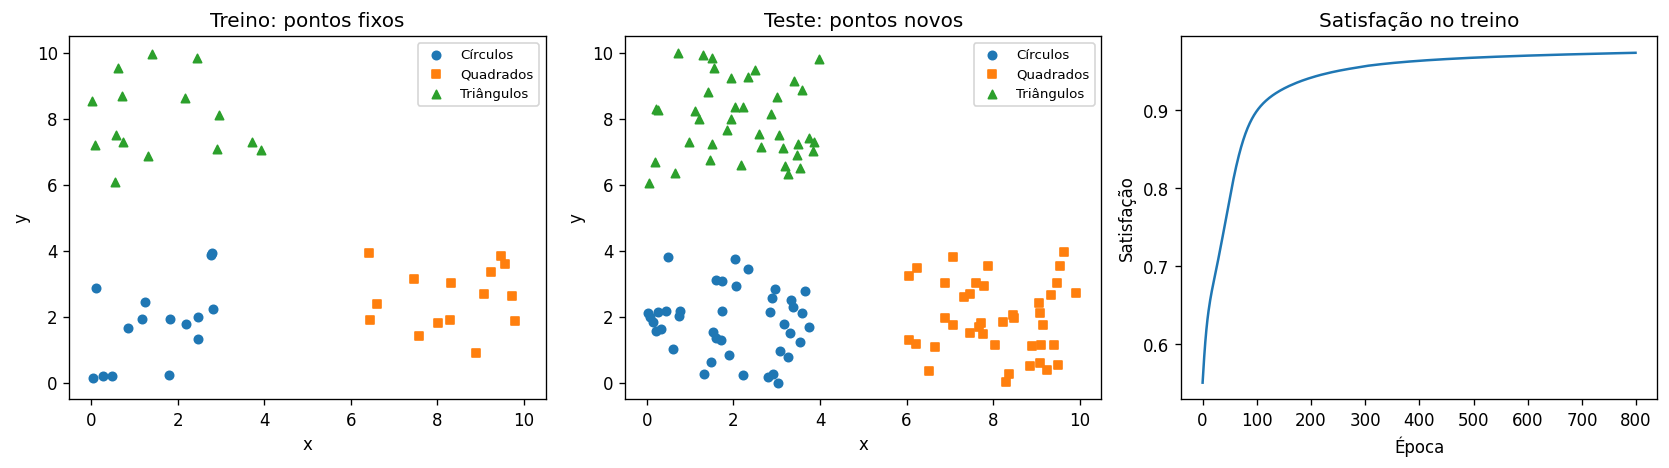

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, data, title in zip(axes[:2], [train_data, test_data], ["Treino: pontos fixos", "Teste: pontos novos"]):
    for points, marker, name in zip(data, ["o", "s", "^"], ["Círculos", "Quadrados", "Triângulos"]):
        ax.scatter(points[:, 0], points[:, 1], marker=marker, label=name, s=25)
    ax.set(xlim=(-0.5, 10.5), ylim=(-0.5, 10.5), xlabel="x", ylabel="y", title=title)
    ax.legend(fontsize=8)
axes[2].plot(history)
axes[2].set(title="Satisfação no treino", xlabel="Época", ylabel="Satisfação")
plt.tight_layout()
plt.show()

### Como interpretar
Valores de verdade perto de 1 indicam maior satisfação; perto de 0 indicam menor satisfação. Não são probabilidades calibradas.
Acurácia compara o limiar 0,5 com a resposta calculada pelas coordenadas. A acurácia balanceada dá o mesmo peso a positivos e negativos; isso é importante porque poucos pares estão próximos.
Uma implicação alta sozinha não basta: também mostrei classes, relações diretas e positivos/negativos.
O teste novo mede generalização neste cenário sintético. O teste no plano amplia a verificação das relações; não demonstra reconhecimento de formas em imagens nem garante desempenho em qualquer distribuição.
A definição de Overlaps usa distância e exclui coordenadas idênticas; não distingue dois objetos diferentes no mesmo centro, pois o exercício só representa coordenadas.

### Resultado desta execução
A satisfação geométrica passou de **0,5504 para 0,9739**. No teste novo, as classes tiveram **100%** de acerto. As relações tiveram **99,86% (LeftOf)**, **99,73% (Above)** e **99,78% (Overlaps)**. Isso mostra generalização nos dados sintéticos avaliados, dentro das limitações descritas acima.

A implicação fuzzy de Reichenbach pode dar menos de 1 mesmo para A → A quando A tem valor intermediário. Por isso, o valor da consulta de simetria não precisa ser exatamente 1, embora a distância seja simétrica.

Os experimentos de igualdade da Parte 1 foram mantidos como demonstrações do professor. Nem todos atingem satisfação máxima; isso não significa falha de execução. A avaliação da extensão geométrica está na Parte 2.

Execução verificada célula a célula em Python 3.12, CPU, PyTorch 2.15.0+cpu, NumPy 1.26.4, LTNtorch 1.0.2 e Matplotlib 3.10.8. As saídas e o gráfico foram capturados dessa execução. Não foi executado em uma sessão do Colab.